# Modelo VAEP Baseline
- **Objetivo:** Estabelecer uma linha de base de performance.
- **Metodologia:** Um modelo VAEP atômico padrão é treinado utilizando exclusivamente features derivadas dos dados de evento SPADL. Este modelo serve como nosso ponto de referência.

In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.vaep import features as ft
from socceraction.vaep import labels as lab
from socceraction.vaep import formula as fm
from socceraction.atomic.spadl import convert_to_atomic
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns
import os

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
df_spadl = pd.read_parquet('spadl_events/spadl_ltr2.parquet')
df_spadl.head()

df_spadl['start_x'] = df_spadl['start_x'] * 105.0
df_spadl['start_y'] = df_spadl['start_y'] * 68.0
df_spadl['end_x'] = df_spadl['end_x'] * 105.0
df_spadl['end_y'] = df_spadl['end_y'] * 68.0

In [4]:
## Mantendo apenas a primeira linha de cada event_id

df_spadl = df_spadl.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

df_spadl['result_name'] = df_spadl['result_id'].map({
    1: 'success',
    0: 'fail'
})

In [5]:
# Ordenar ações por tempo dentro de cada jogo
df_spadl = df_spadl.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

## Conversão de SPADL para Atomic SPADL

In [6]:
df_atomic = convert_to_atomic(df_spadl)
df_atomic = df_atomic[df_atomic['original_event_id'].notna()]
df_atomic.reset_index(drop=True, inplace=True)
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5
1,13335,12926009.0,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0
2,13335,12926647.0,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5
3,13335,12926642.0,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
520879,13621,18803885.0,601140,2,6067.134,218.0,102,65.365,58.755,NaN,NaN,9,0
520880,13621,18803906.0,601141,2,6095.830,218.0,102,75.750,54.667,20.560,-30.762,0,5
520881,13621,18803919.0,601142,2,6098.732,218.0,567,96.310,23.905,NaN,NaN,9,0
520882,13621,18803920.0,601143,2,6098.765,218.0,567,96.432,23.710,5.675,8.382,0,1


Adicionar a coluna `type_name` ao Atomic SPADL:

In [7]:
from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

## Baseline Atomic VAEP

In [8]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

### Features

In [9]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 3
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features: 100%|██████████| 232/232 [00:26<00:00,  8.65it/s]


### Labels

In [10]:
Ycols = ["scores","concedes"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts)], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels: 100%|██████████| 232/232 [00:24<00:00,  9.59it/s]


In [11]:
# Garante que features e labels têm o mesmo índice sequencial do df_atomic
features = features.reset_index(drop=True)
labels   = labels.reset_index(drop=True)

# Checagem de sanidade: todos os comprimentos batem?
assert len(features) == len(labels) == len(df_atomic), (
    f"Desalinhamento de índices: "
    f"df_atomic={len(df_atomic)}, features={len(features)}, labels={len(labels)}"
)
# —————————————————

In [12]:
# Index das linhas que contêm gols
mask_goal = features['actiontype_goal_a0'] == True

# Remover as linhas que contêm gols
features = features[~mask_goal]
labels = labels[~mask_goal]
features.shape, labels.shape

((520061, 142), (520061, 2))

In [13]:
# remove a coluna index de features e labels
# features = features.drop(columns=['index'])
# labels = labels.drop(columns=['index'])

In [14]:
# remove também as linhas que contêm gols de df_atomic
print(f"Antes de remover gols: {df_atomic.shape}")
df_atomic = df_atomic[df_atomic.type_name != 'goal'].reset_index(drop=True)
print(f"Depois de remover gols: {df_atomic.shape}")

Antes de remover gols: (520884, 14)
Depois de remover gols: (520061, 14)


In [15]:
# teste rápido de alinhamento
assert len(df_atomic) == features.shape[0] == labels.shape[0], "Indices desalinhados!"

## Divisão Treino/Teste

In [16]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(
    gss.split(df_atomic, groups=df_atomic.game_id)
)

mask_train = df_atomic.index.isin(train_idx)
mask_test  = df_atomic.index.isin(test_idx)


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)

In [17]:
X_train.shape[0] + X_test.shape[0], y_train.shape[0] + y_test.shape[0]

(520061, 520061)

## Treino - Atomic VAEP

In [18]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p, dtype=float)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

In [ ]:
models, yhat_train, yhat_test = {}, {}, {}
for target in ['scores', 'concedes']:
    print(f"\n### Treinando '{target}' ###")
    clf = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        enable_categorical=True,
        n_jobs=-3,
        subsample=0.6,
        learning_rate=0.01,
        colsample_bytree=0.6,
        random_state=42
    )
    clf.fit(X_train, y_train[target])
    models[target] = clf

    yhat_train[target] = clf.predict_proba(X_train)[:, 1]
    yhat_test[target] = clf.predict_proba(X_test)[:, 1]

    print(f"Modelo '{target}' treinado.")
    evaluate(y_train[target], yhat_train[target], label=f"train {target}")
    evaluate(y_test[target], yhat_test[target], label=f"test {target}")


### Treinando 'scores' ###
Modelo 'scores' treinado.
### TRAIN SCORES ###
  Brier score : 0.01148 (0.94955)
  Log loss    : 0.05676 (0.85912)
  ROC AUC     : 0.79688

### TEST SCORES ###
  Brier score : 0.01008 (0.95781)
  Log loss    : 0.05153 (0.87466)
  ROC AUC     : 0.78551


### Treinando 'concedes' ###
Modelo 'concedes' treinado.
### TRAIN CONCEDES ###
  Brier score : 0.00238 (0.98748)
  Log loss    : 0.01507 (0.88909)
  ROC AUC     : 0.79763

### TEST CONCEDES ###
  Brier score : 0.00175 (0.99092)
  Log loss    : 0.01166 (0.89707)
  ROC AUC     : 0.82364



## Avaliação da Feature Importance


Top 10 features por ganho (total_gain):
Index(['total_gain'], dtype='object')


<Axes: title={'center': 'Top 10 Feature Importances (total_gain)'}>

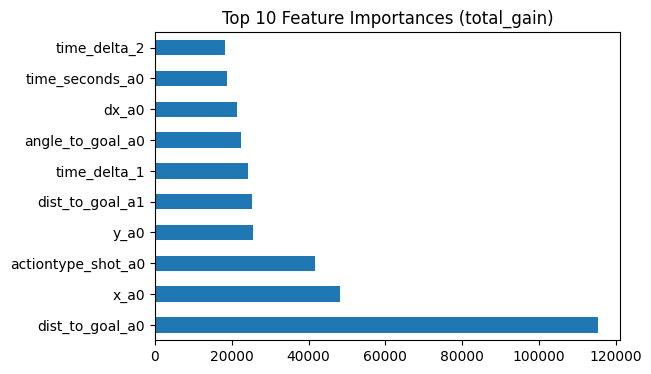

In [ ]:
scores_model = models['scores']
booster = scores_model.get_booster()
imp_dict = booster.get_score(importance_type='total_gain')

import pandas as pd
imp_df = (
    pd.DataFrame.from_dict(imp_dict, orient='index', columns=['total_gain'])
      .sort_values('total_gain', ascending=False)
)
print("\nTop 10 features por ganho (total_gain):")
print(imp_df.keys())

# Se quiser visualizar graficamente:
imp_df.head(10).plot.barh(figsize=(6,4), legend=False, title="Top 10 Feature Importances (total_gain)")

# Diagnóstico Visual dos Modelos Baseline

In [ ]:
Y_hat_train_final = pd.DataFrame()
Y_hat_test_final = pd.DataFrame()

for target in ['scores', 'concedes']:
    # Usamos os modelos do 'final_vaep_models' para prever nos conjuntos de treino e teste
    # Note que X_train e X_test aqui são os que contêm a coluna 'success_score'
    Y_hat_train_final[target] = models[target].predict_proba(X_train)[:, 1]
    Y_hat_test_final[target] = models[target].predict_proba(X_test)[:, 1]

print("Predições dos modelos finais coletadas.")

Predições dos modelos finais coletadas.


In [ ]:
# %%
# --- ETAPA 9.2: Definição da Função de Plotagem ---
# (Esta é a sua função, copiada aqui para manter a célula autocontida)

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10, strategy='uniform')
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10, strategy='uniform')

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid(True)

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.legend()
    plt.grid(True)

    # -------- Distribuição das Probabilidades Previstas --------
    plt.subplot(1, 3, 3)
    sns.kdeplot(yhat_train, label='Treino', fill=True)
    sns.kdeplot(yhat_test, label='Teste', fill=True)
    plt.title(f'Distribuição de Probabilidades - {label}')
    plt.xlabel('Probabilidade prevista')
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###



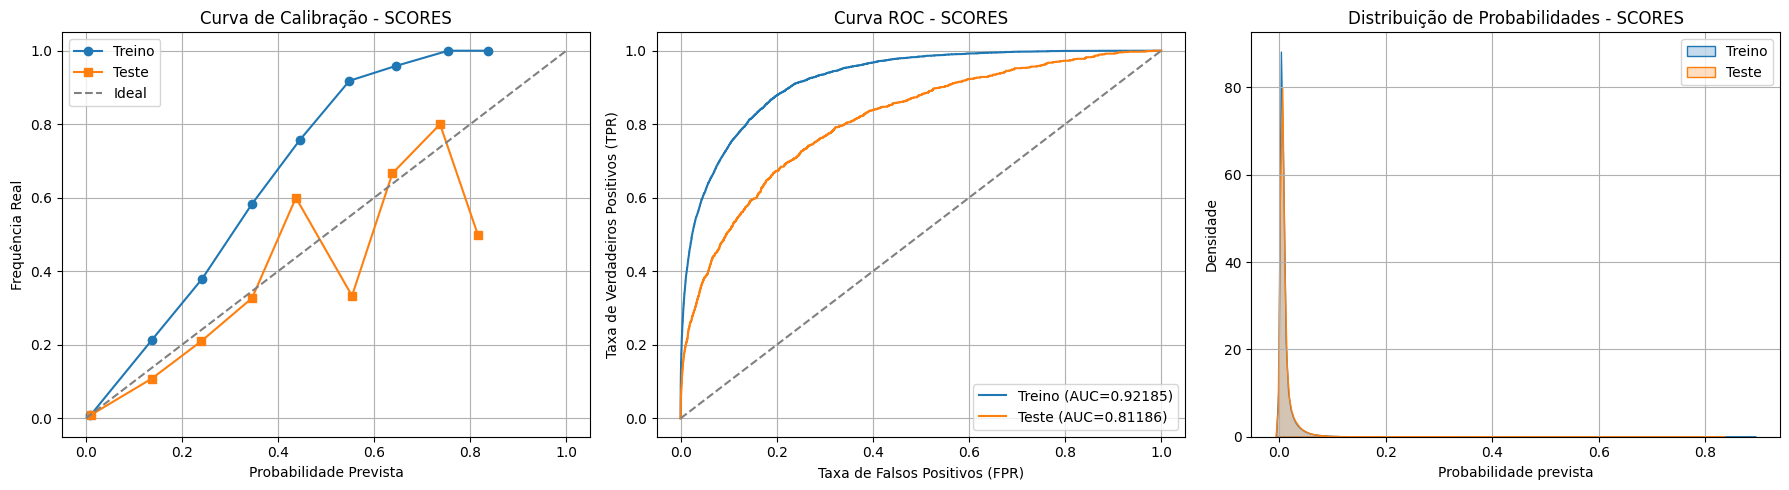

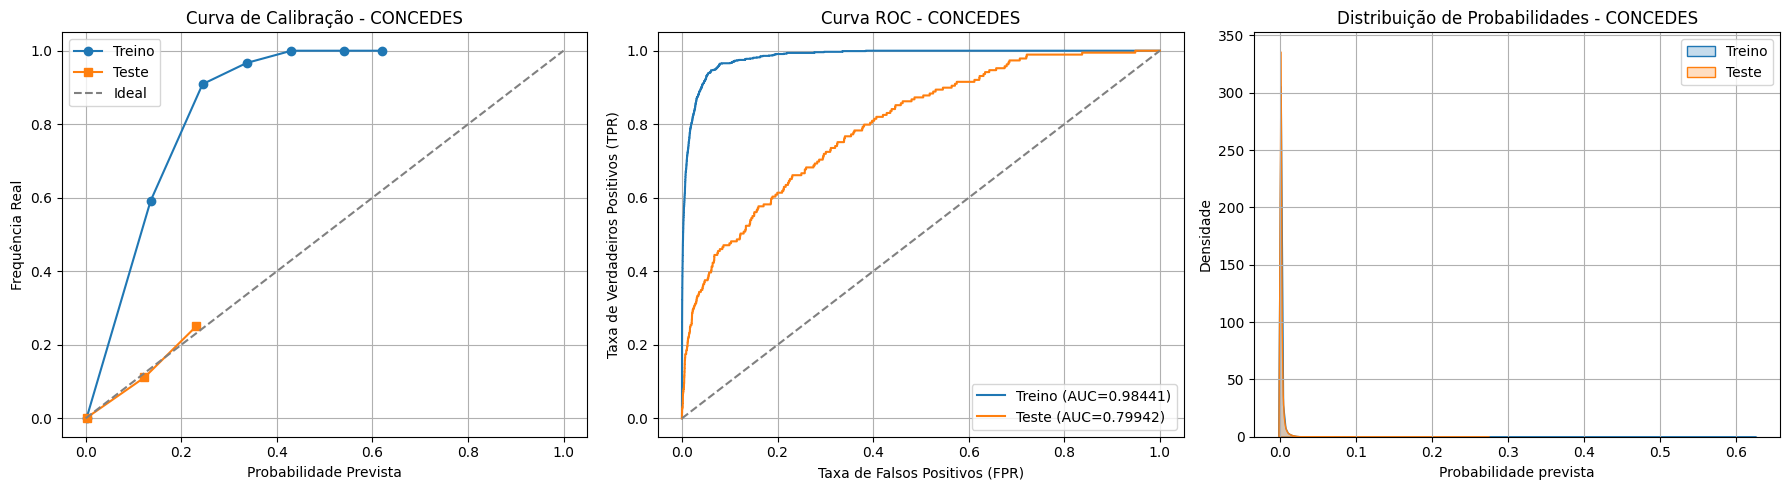

In [ ]:
print("\n### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###\n")

for col in ['scores', 'concedes']:
    plot_model_diagnostics(
        y_train[col], 
        y_test[col], 
        Y_hat_train_final[col], 
        Y_hat_test_final[col], 
        label=col.upper()
    )